<a href="https://colab.research.google.com/github/abrarjahinzihan/Car_Price_Prediction/blob/main/Car_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚗 Car Price Prediction (Used Cars) — Random Forest Regression

**Goal:** Estimate the resale value of used vehicles from historical market listings.

**Features used:** brand, vehicle model, age, odometer mileage (km run), engine capacity, transmission type and fuel type.

**Pipeline**
1. Mount Google Drive & load data
2. Clean the raw text columns (price, cc, km, fuel)
3. Exploratory data analysis
4. Categorical encoding — **One-Hot** (brand, transmission, fuel) and **Target Encoding** (model)
5. Train a **Random Forest Regressor** (+ compare against a linear baseline and a pure One-Hot variant)
6. Hyper-parameter tuning, evaluation, feature importance
7. Tools for **buyers** (is this listing fairly priced?) and **sellers** (what price is competitive?)
8. Save the model

## 1. Mount Google Drive and load the data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# >>> Change this path to where you uploaded the CSV in your Google Drive <<<
DATA_PATH = '/content/drive/MyDrive/Untitled Folder 2/UsedCarInfo.csv'

# Where the trained model will be saved
SAVE_DIR = '/content/drive/MyDrive'

In [4]:
import re, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
RANDOM_STATE = 42

In [5]:
df_raw = pd.read_csv(DATA_PATH)
print('Shape:', df_raw.shape)
df_raw.head(10)

Shape: (5997, 10)


,title,brand,model,transmission,fuel_type,price,year_of_manufacture,energy_capacity,kilometers_run,car_age
0,Toyota Corolla CR 13.REG 1999.MODEL 1996,Toyota,Corolla,Automatic,"CNG, Octane","Tk 530,000",1996,"1,500 cc","89,000 km",30
1,Toyota Corolla Cross 2023,Toyota,Corolla Cross,Automatic,"Hybrid, Octane","Tk 5,500,000",2025,"1,800 cc","15,500 km",1
2,Toyota RAV4 CR 13.REG 2011.MODEL 2005,Toyota,RAV4,Automatic,"Octane, LPG","Tk 1,370,000",2005,"1,800 cc","87,000 km",21
3,Toyota Allion CR 23.REG 2010.MODEL 2004,Toyota,Allion,Automatic,"CNG, Octane","Tk 1,350,000",2004,"1,500 cc","89,000 km",22
4,Toyota Hiace 2015,Toyota,Hiace,Automatic,"CNG, Octane","Tk 2,750,000",2020,"2,000 cc","190,000 km",6
5,Toyota Premio F 2014,Toyota,Premio,Automatic,Octane,"Tk 2,480,000",2014,"1,500 cc","63,000 km",12
6,Toyota Axio EX 2020,Toyota,Axio,Automatic,Octane,"Tk 2,400,000",2020,"1,500 cc","50,868 km",6
7,Toyota Axio 2017,Toyota,Axio,Automatic,"Hybrid, Octane","Tk 2,000,000",2023,"1,500 cc","86,000 km",3
8,Toyota Axio X 2013,Toyota,Axio,Automatic,Octane,"Tk 1,670,000",2013,"1,500 cc","64,000 km",13
9,Toyota Fielder G Edition Top Trim 2007,Toyota,Fielder,Automatic,Octane,"Tk 1,320,000",2007,"1,500 cc","290,000 km",19


In [6]:
df_raw.info()
print('\nMissing values per column:')
print(df_raw.isna().sum())
print('\nDuplicate rows:', df_raw.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5997 entries, 0 to 5996
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   title                5997 non-null   object
 1   brand                5997 non-null   object
 2   model                5997 non-null   object
 3   transmission         5997 non-null   object
 4   fuel_type            5997 non-null   object
 5   price                5997 non-null   object
 6   year_of_manufacture  5997 non-null   int64 
 7   energy_capacity      5997 non-null   object
 8   kilometers_run       5997 non-null   object
 9   car_age              5997 non-null   int64 
dtypes: int64(2), object(8)
memory usage: 468.6+ KB

Missing values per column:
title                  0
brand                  0
model                  0
transmission           0
fuel_type              0
price                  0
year_of_manufacture    0
energy_capacity        0
kilometers_run         0


## 2. Data cleaning

The raw file stores numbers as text (`"Tk 530,000"`, `"1,500 cc"`, `"89,000 km"`) and a car can run on **several fuels** (`"CNG, Octane"`).
We convert everything to numeric form and turn fuel type into one indicator column per fuel.

> Note: `car_age` equals `2026 − year_of_manufacture`, so it carries the same information. We keep `car_age` only.

In [7]:
def to_number(series):
    # Strip everything except digits and the decimal point, then convert to float
    return pd.to_numeric(series.astype(str).str.replace(r'[^0-9.]', '', regex=True), errors='coerce')

df = df_raw.copy()
df['price_tk']  = to_number(df['price'])
df['engine_cc'] = to_number(df['energy_capacity'])
df['km_run']    = to_number(df['kilometers_run'])

# Tidy text columns
for c in ['brand', 'model', 'transmission']:
    df[c] = df[c].astype(str).str.strip()
df['fuel_type'] = df['fuel_type'].fillna('Unknown').astype(str)

df[['price_tk', 'engine_cc', 'km_run', 'car_age']].describe()

,price_tk,engine_cc,km_run,car_age
count,"5,997.00","5,997.00","5,997.00","5,997.00"
mean,"4,076,050.26","33,438,517.59","65,653.86",8.18
std,"4,973,530.11","2,589,350,768.12","47,395.80",5.89
min,"46,189.00",50.00,0.00,0.00
25%,"2,349,999.00","1,500.00","43,000.00",5.00
50%,"3,380,000.00","1,800.00","63,545.00",6.00
75%,"4,400,000.00","2,000.00","83,170.00",8.00
max,"105,000,000.00","200,520,101,000.00","950,000.00",65.00


In [8]:
# ---- Fuel type: multi-label -> one indicator column per fuel ----
fuel_lists = df['fuel_type'].apply(lambda s: [t.strip() for t in s.split(',') if t.strip()])
fuel_counts = pd.Series([t for lst in fuel_lists for t in lst]).value_counts()
print(fuel_counts)

MIN_FUEL_COUNT = 20                       # ignore extremely rare fuel labels
FUELS = [f for f, n in fuel_counts.items() if n >= MIN_FUEL_COUNT and f != 'Unknown']
FUEL_COLS = ['fuel_' + re.sub(r'\W+', '_', f.lower()) for f in FUELS]

for f, col in zip(FUELS, FUEL_COLS):
    df[col] = fuel_lists.apply(lambda lst, f=f: int(f in lst))

print('\nFuel indicator columns:', FUEL_COLS)

Octane             4439
Hybrid             2827
Petrol             2450
CNG                 517
LPG                 197
Diesel               74
Other fuel type      46
Electric              6
Unknown               3
Name: count, dtype: int64

Fuel indicator columns: ['fuel_octane', 'fuel_hybrid', 'fuel_petrol', 'fuel_cng', 'fuel_lpg', 'fuel_diesel', 'fuel_other_fuel_type']


In [9]:
n0 = len(df)

# 1) drop exact duplicates and rows missing key values
df = df.drop_duplicates()
df = df.dropna(subset=['price_tk', 'engine_cc', 'km_run', 'car_age', 'brand', 'model', 'transmission'])

# 2) remove impossible / junk listings (placeholder prices, negative age, absurd mileage or engine size)
df = df[(df['price_tk'] >= 50_000)]
df = df[(df['car_age'] >= 0)]
df = df[(df['km_run'] > 0) & (df['km_run'] <= 1_000_000)]
df = df[(df['engine_cc'] >= 600) & (df['engine_cc'] <= 8_000)]

# 3) trim the extreme 0.5% tails of price (extreme outliers / typos)
lo, hi = df['price_tk'].quantile([0.005, 0.995])
df = df[df['price_tk'].between(lo, hi)]

df = df.reset_index(drop=True)
print(f'Rows before: {n0:,} | after cleaning: {len(df):,} | removed: {n0-len(df):,}')
print(f'Price range kept: Tk {lo:,.0f} – Tk {hi:,.0f}')

Rows before: 5,997 | after cleaning: 5,899 | removed: 98
Price range kept: Tk 450,000 – Tk 24,043,000


In [10]:
# ---- Feature engineering ----
df['km_per_year'] = df['km_run'] / df['car_age'].clip(lower=1)

NUM_COLS    = ['car_age', 'km_run', 'engine_cc', 'km_per_year'] + FUEL_COLS
OHE_COLS    = ['brand', 'transmission']
TARGET_COLS = ['model']
FEATURES    = NUM_COLS + OHE_COLS + TARGET_COLS

df[FEATURES + ['price_tk']].head()

,car_age,km_run,engine_cc,km_per_year,fuel_octane,fuel_hybrid,fuel_petrol,fuel_cng,fuel_lpg,fuel_diesel,fuel_other_fuel_type,brand,transmission,model,price_tk
0,30,89000,1500,"2,966.67",1,0,0,1,0,0,0,Toyota,Automatic,Corolla,530000
1,1,15500,1800,"15,500.00",1,1,0,0,0,0,0,Toyota,Automatic,Corolla Cross,5500000
2,21,87000,1800,"4,142.86",1,0,0,0,1,0,0,Toyota,Automatic,RAV4,1370000
3,22,89000,1500,"4,045.45",1,0,0,1,0,0,0,Toyota,Automatic,Allion,1350000
4,6,190000,2000,"31,666.67",1,0,0,1,0,0,0,Toyota,Automatic,Hiace,2750000


## 3. Exploratory data analysis

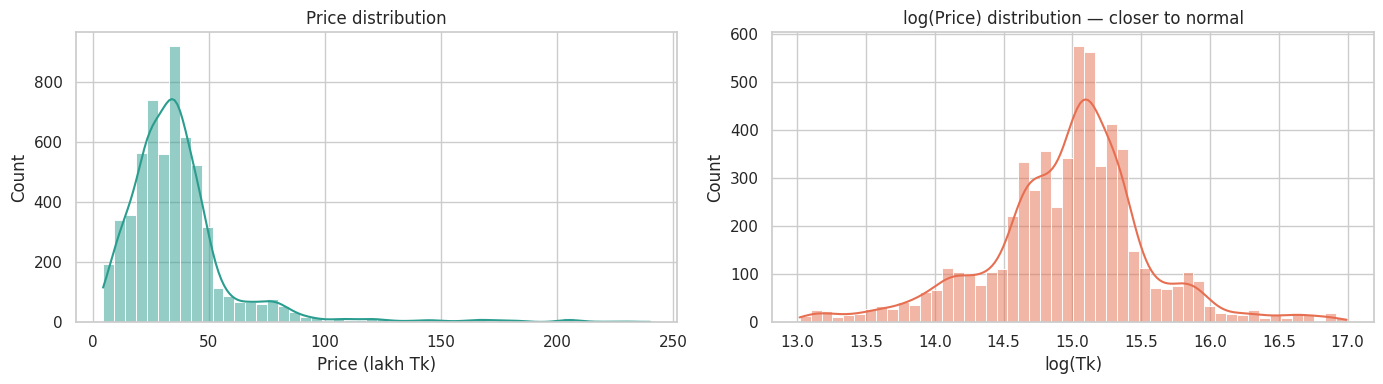

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['price_tk'] / 1e5, bins=50, kde=True, ax=axes[0], color='#2a9d8f')
axes[0].set(title='Price distribution', xlabel='Price (lakh Tk)')
sns.histplot(np.log1p(df['price_tk']), bins=50, kde=True, ax=axes[1], color='#e76f51')
axes[1].set(title='log(Price) distribution — closer to normal', xlabel='log(Tk)')
plt.tight_layout(); plt.show()

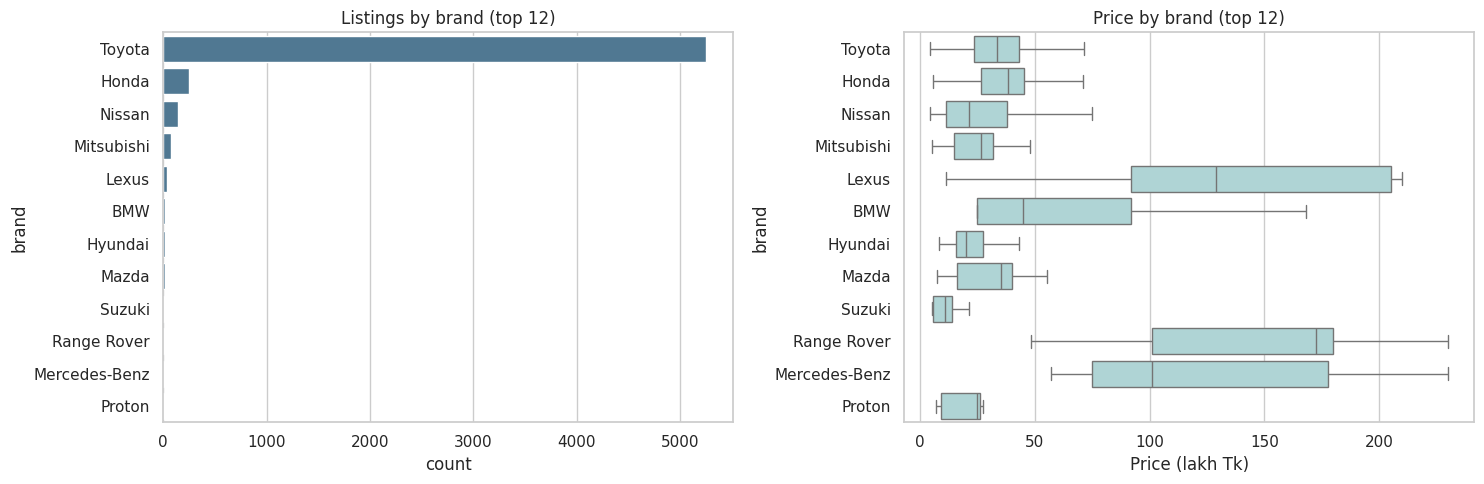

In [12]:
top_brands = df['brand'].value_counts().head(12).index
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(y='brand', data=df[df.brand.isin(top_brands)], order=top_brands, ax=axes[0], color='#457b9d')
axes[0].set(title='Listings by brand (top 12)')
sns.boxplot(y='brand', x=df['price_tk']/1e5, data=df[df.brand.isin(top_brands)], order=top_brands,
            ax=axes[1], color='#a8dadc', showfliers=False)
axes[1].set(title='Price by brand (top 12)', xlabel='Price (lakh Tk)')
plt.tight_layout(); plt.show()

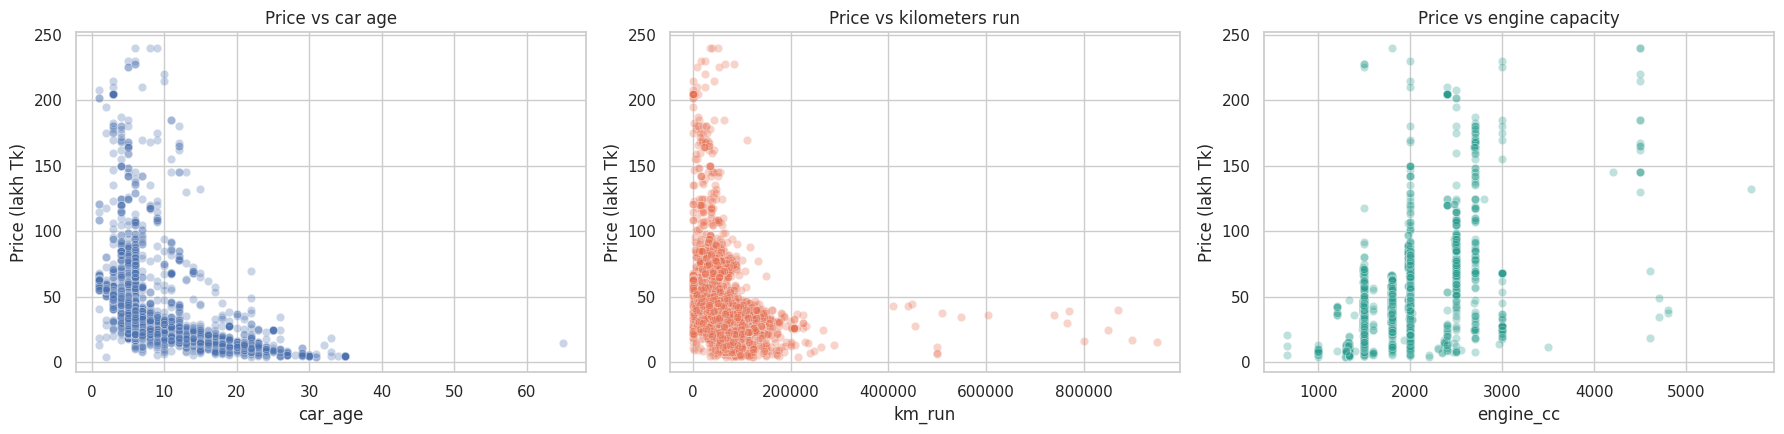

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.scatterplot(x='car_age', y=df['price_tk']/1e5, data=df, alpha=.3, ax=axes[0])
axes[0].set(title='Price vs car age', ylabel='Price (lakh Tk)')
sns.scatterplot(x='km_run', y=df['price_tk']/1e5, data=df, alpha=.3, ax=axes[1], color='#e76f51')
axes[1].set(title='Price vs kilometers run', ylabel='Price (lakh Tk)')
sns.scatterplot(x='engine_cc', y=df['price_tk']/1e5, data=df, alpha=.3, ax=axes[2], color='#2a9d8f')
axes[2].set(title='Price vs engine capacity', ylabel='Price (lakh Tk)')
plt.tight_layout(); plt.show()

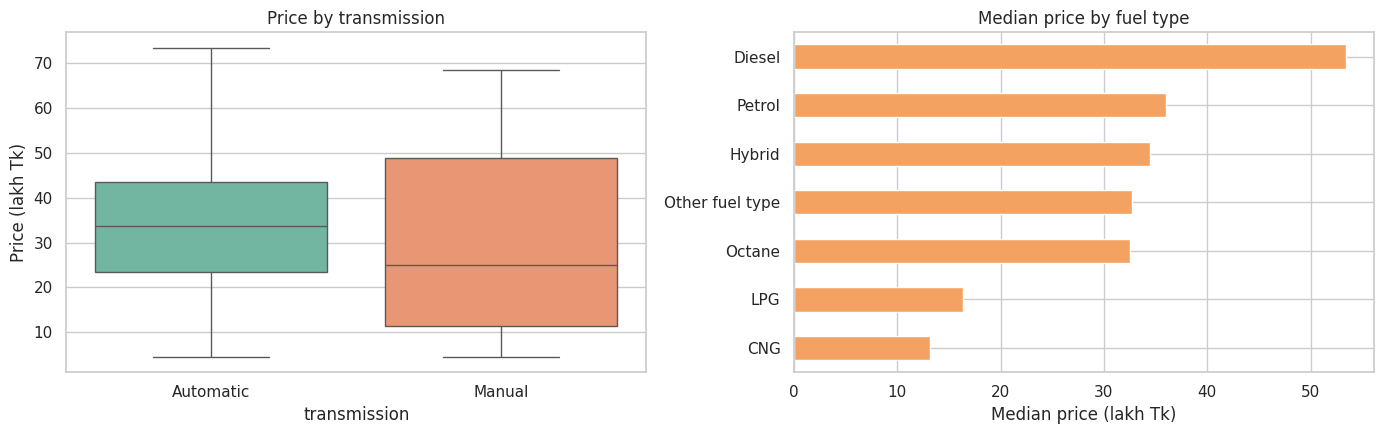

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(x='transmission', y=df['price_tk']/1e5, data=df, ax=axes[0], showfliers=False, palette='Set2')
axes[0].set(title='Price by transmission', ylabel='Price (lakh Tk)')

fuel_price = pd.Series({f: df.loc[df[c] == 1, 'price_tk'].median() / 1e5 for f, c in zip(FUELS, FUEL_COLS)}).sort_values()
fuel_price.plot.barh(ax=axes[1], color='#f4a261')
axes[1].set(title='Median price by fuel type', xlabel='Median price (lakh Tk)')
plt.tight_layout(); plt.show()

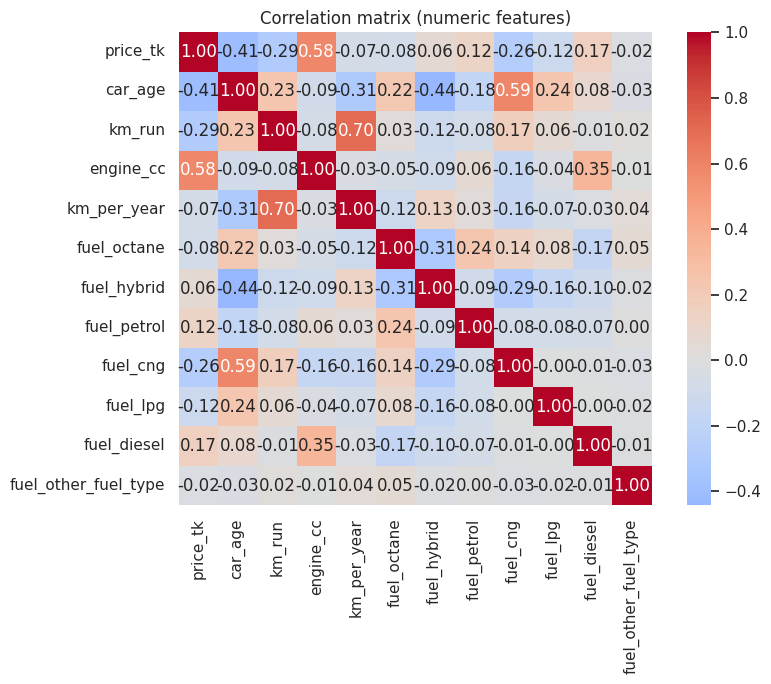

In [15]:
plt.figure(figsize=(9, 7))
corr = df[['price_tk', 'car_age', 'km_run', 'engine_cc', 'km_per_year'] + FUEL_COLS].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation matrix (numeric features)')
plt.tight_layout(); plt.show()

## 4. Encoding strategy & train/test split

| Feature | Type | Encoding | Why |
|---|---|---|---|
| `brand`, `transmission` | low cardinality | **One-Hot** (rare brands grouped as "infrequent") | few categories |
| `fuel_*` | multi-label | indicator (0/1) columns | a car can use several fuels |
| `model` | high cardinality | **Target Encoding** (cross-fitted, so no target leakage) | One-Hot would create hundreds of sparse columns |
| numeric features | — | passed through (trees don't need scaling) | |

The target is modelled on a **log scale** (prices are right-skewed) and converted back to Tk for all reported metrics.

In [16]:
X = df[FEATURES]
y = df['price_tk']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (4719, 14) | Test: (1180, 14)


In [17]:
def make_preprocessor(model_encoding='target'):
    # model_encoding: 'target' -> TargetEncoder for `model`; 'onehot' -> One-Hot for `model` too
    ohe = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=10, sparse_output=False)
    if model_encoding == 'target':
        return ColumnTransformer([
            ('num', 'passthrough', NUM_COLS),
            ('ohe', ohe, OHE_COLS),
            ('te', TargetEncoder(target_type='continuous', smooth='auto', random_state=RANDOM_STATE), TARGET_COLS),
        ])
    return ColumnTransformer([
        ('num', 'passthrough', NUM_COLS),
        ('ohe', ohe, OHE_COLS + TARGET_COLS),
    ])

def make_pipeline(model_encoding='target', **rf_params):
    rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **rf_params)
    pipe = Pipeline([('prep', make_preprocessor(model_encoding)), ('rf', rf)])
    # Fit on log(price), predict in Tk
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

def evaluate(model, X_tr, y_tr, X_te, y_te, name):
    pred = model.predict(X_te)
    return {
        'Model': name,
        'MAE (Tk)':  mean_absolute_error(y_te, pred),
        'RMSE (Tk)': np.sqrt(mean_squared_error(y_te, pred)),
        'R²':        r2_score(y_te, pred),
        'MAPE (%)':  np.mean(np.abs((y_te - pred) / y_te)) * 100,
        'Median APE (%)': np.median(np.abs((y_te - pred) / y_te)) * 100,
    }

## 5. Baseline vs Random Forest (and which `model` encoding is better?)

In [18]:
results = []

# Baseline: Ridge regression with One-Hot everywhere (scaled numerics)
ridge_prep = ColumnTransformer([
    ('num', StandardScaler(), NUM_COLS),
    ('ohe', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=10, sparse_output=False),
     OHE_COLS + TARGET_COLS),
])
ridge = TransformedTargetRegressor(regressor=Pipeline([('prep', ridge_prep), ('ridge', Ridge(alpha=1.0))]),
                                   func=np.log1p, inverse_func=np.expm1)
ridge.fit(X_train, y_train)
results.append(evaluate(ridge, X_train, y_train, X_test, y_test, 'Ridge baseline (One-Hot)'))

# Random Forest — One-Hot for `model`
rf_ohe = make_pipeline('onehot').fit(X_train, y_train)
results.append(evaluate(rf_ohe, X_train, y_train, X_test, y_test, 'Random Forest (One-Hot model)'))

# Random Forest — Target Encoding for `model`
rf_te = make_pipeline('target').fit(X_train, y_train)
results.append(evaluate(rf_te, X_train, y_train, X_test, y_test, 'Random Forest (Target-encoded model)'))

pd.DataFrame(results).set_index('Model')

,MAE (Tk),RMSE (Tk),R²,MAPE (%),Median APE (%)
Model,,,,,
Ridge baseline (One-Hot),"462,488.66","1,163,364.75",0.81,12.36,7.79
Random Forest (One-Hot model),"330,488.59","933,175.82",0.88,9.49,4.79
Random Forest (Target-encoded model),"340,260.08","982,722.55",0.87,9.71,4.99


In [19]:
# 5-fold cross-validation on the training set (R² on the Tk scale)
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for name, mdl in [('Ridge baseline', ridge),
                  ('RF One-Hot', make_pipeline('onehot')),
                  ('RF Target Enc.', make_pipeline('target'))]:
    s = cross_val_score(mdl, X_train, y_train, cv=kf, scoring='r2', n_jobs=1)
    cv_scores[name] = s
    print(f'{name:16s} R² = {s.mean():.4f} ± {s.std():.4f}')

best_encoding = 'target' if cv_scores['RF Target Enc.'].mean() >= cv_scores['RF One-Hot'].mean() else 'onehot'
print('\nBest encoding for `model` by CV:', best_encoding)

Ridge baseline   R² = 0.7875 ± 0.0424
RF One-Hot       R² = 0.8557 ± 0.0513
RF Target Enc.   R² = 0.8579 ± 0.0522

Best encoding for `model` by CV: target


## 6. Hyper-parameter tuning (Random Forest)

In [21]:
param_dist = {
    'regressor__rf__n_estimators':      [200, 300, 500, 700],
    'regressor__rf__max_depth':         [None, 12, 18, 25],
    'regressor__rf__min_samples_split': [2, 5, 10],
    'regressor__rf__min_samples_leaf':  [1, 2, 4],
    'regressor__rf__max_features':      ['sqrt', 0.5, 0.7, 1.0],
}

search = RandomizedSearchCV(
    make_pipeline(best_encoding),
    param_distributions=param_dist,
    n_iter=20, cv=3, scoring='neg_mean_absolute_error',
    random_state=RANDOM_STATE, n_jobs=1, verbose=1,
)
search.fit(X_train, y_train)

print('Best params:')
for k, v in search.best_params_.items():
    print(f'  {k.replace("regressor__rf__", "")}: {v}')
best_model = search.best_estimator_

Best params:
  n_estimators: 500
  min_samples_split: 2
  min_samples_leaf: 1
  max_features: 0.5
  max_depth: 25
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params:
  n_estimators: 500
  min_samples_split: 2
  min_samples_leaf: 1
  max_features: 0.5
  max_depth: 25


In [22]:
results.append(evaluate(best_model, X_train, y_train, X_test, y_test, 'Random Forest (tuned)'))
comparison = pd.DataFrame(results).set_index('Model')
comparison

,MAE (Tk),RMSE (Tk),R²,MAPE (%),Median APE (%)
Model,,,,,
Ridge baseline (One-Hot),"462,488.66","1,163,364.75",0.81,12.36,7.79
Random Forest (One-Hot model),"330,488.59","933,175.82",0.88,9.49,4.79
Random Forest (Target-encoded model),"340,260.08","982,722.55",0.87,9.71,4.99
Random Forest (tuned),"335,795.36","1,005,036.77",0.86,9.49,5.05


## 7. Evaluation of the final model

80% of test cars sold between 0.88x and 1.12x of the predicted price


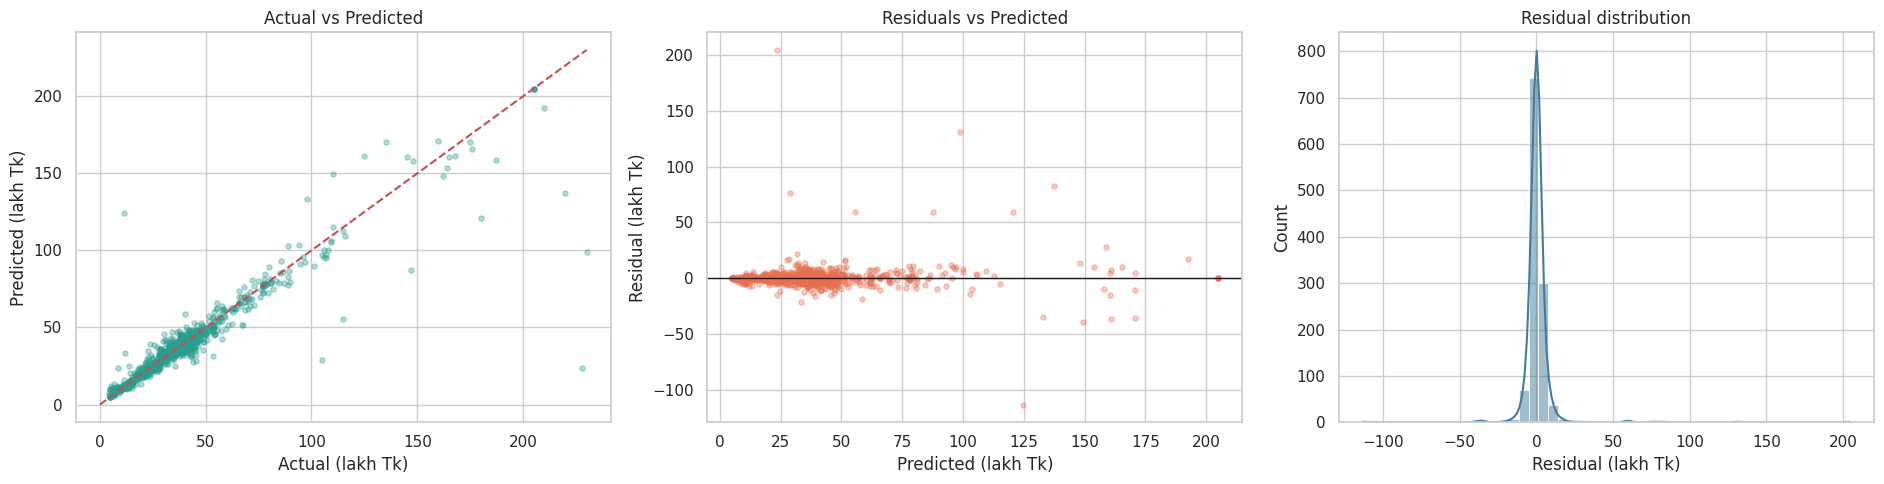

Test R²: 0.859 | MAE: Tk 335,795 | Median error: 5.1%


In [23]:
y_pred = best_model.predict(X_test)
residuals = y_test - y_pred

# Calibrated price range: 10th-90th percentile of (actual / predicted) on the held-out test set
RATIO_LO, RATIO_HI = np.quantile(y_test / y_pred, [0.10, 0.90])
print(f'80% of test cars sold between {RATIO_LO:.2f}x and {RATIO_HI:.2f}x of the predicted price')

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].scatter(y_test/1e5, y_pred/1e5, alpha=.35, s=14, color='#2a9d8f')
lim = [0, max(y_test.max(), y_pred.max())/1e5]
axes[0].plot(lim, lim, 'r--', lw=1.5)
axes[0].set(title='Actual vs Predicted', xlabel='Actual (lakh Tk)', ylabel='Predicted (lakh Tk)')

axes[1].scatter(y_pred/1e5, residuals/1e5, alpha=.35, s=14, color='#e76f51')
axes[1].axhline(0, color='k', lw=1)
axes[1].set(title='Residuals vs Predicted', xlabel='Predicted (lakh Tk)', ylabel='Residual (lakh Tk)')

sns.histplot(residuals/1e5, bins=50, kde=True, ax=axes[2], color='#457b9d')
axes[2].set(title='Residual distribution', xlabel='Residual (lakh Tk)')
plt.tight_layout(); plt.show()

final = comparison.loc['Random Forest (tuned)']
print(f"Test R²: {final['R²']:.3f} | MAE: Tk {final['MAE (Tk)']:,.0f} | Median error: {final['Median APE (%)']:.1f}%")

In [24]:
# Error by price band — where is the model more / less reliable?
band = pd.cut(y_test, bins=[0, 1e6, 2e6, 3e6, 5e6, np.inf],
              labels=['< 10L', '10–20L', '20–30L', '30–50L', '> 50L'])
err = pd.DataFrame({'band': band, 'ape': np.abs(residuals / y_test) * 100})
print(err.groupby('band', observed=True)['ape'].agg(['count', 'median', 'mean']).rename(
    columns={'count': 'cars', 'median': 'median error %', 'mean': 'mean error %'}))

        cars  median error %  mean error %
band                                      
< 10L     46           15.95         33.77
10–20L   150            5.55         15.80
20–30L   268            4.66          7.52
30–50L   550            4.69          6.81
> 50L    166            5.58          9.15


### Feature importance
Permutation importance is computed on the **original** features (so `brand` or `fuel_*` are not split across dozens of dummy columns).

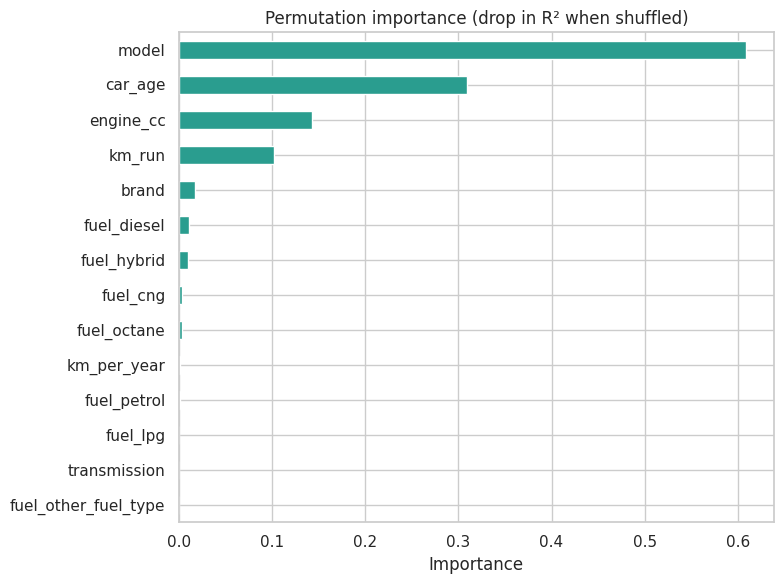

In [25]:
perm = permutation_importance(best_model, X_test, y_test, scoring='r2', n_repeats=8,
                              random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 6))
imp.tail(15).plot.barh(color='#2a9d8f')
plt.title('Permutation importance (drop in R² when shuffled)')
plt.xlabel('Importance'); plt.tight_layout(); plt.show()

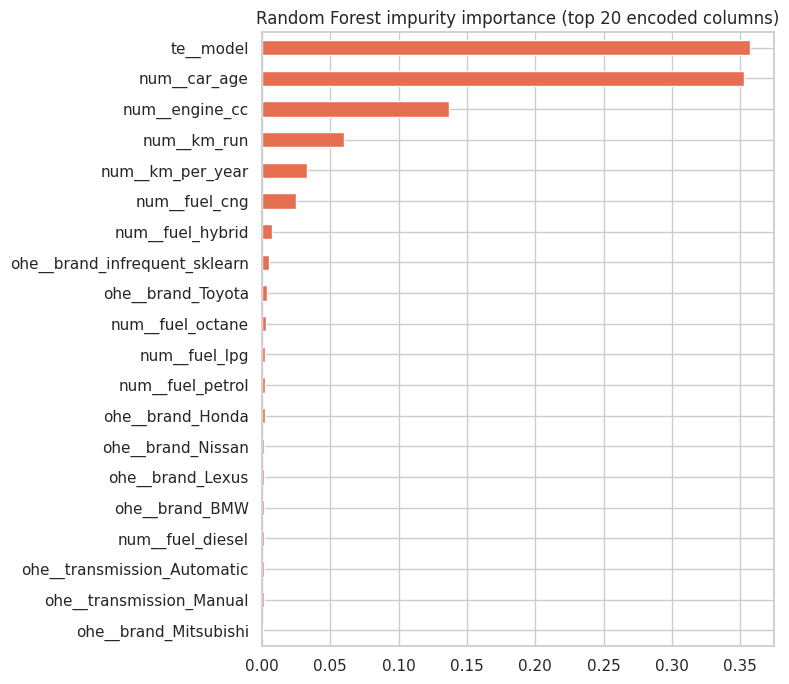

In [26]:
# Impurity-based importance on the encoded columns (alternative view)
fitted_pipe = best_model.regressor_
names = fitted_pipe.named_steps['prep'].get_feature_names_out()
rf_imp = pd.Series(fitted_pipe.named_steps['rf'].feature_importances_, index=names).sort_values()

plt.figure(figsize=(8, 7))
rf_imp.tail(20).plot.barh(color='#e76f51')
plt.title('Random Forest impurity importance (top 20 encoded columns)')
plt.tight_layout(); plt.show()

## 8. Price tools for buyers and sellers

* `predict_price(...)` — estimated market value **plus a likely range** (an 80% interval calibrated on the model's errors on the held-out test set).
* `check_listing(...)` — **buyers:** is an asking price below / within / above the market range?
* `suggest_listing_price(...)` — **sellers:** a quick-sale, fair-market and premium asking price.

In [28]:
DATA_YEAR = 2026   # car_age in the dataset = 2026 - year_of_manufacture

def _make_row(brand, model, transmission, fuels, year, km, cc):
    age = max(DATA_YEAR - year, 0)
    row = {
        'car_age': age, 'km_run': km, 'engine_cc': cc, 'km_per_year': km / max(age, 1),
        'brand': brand, 'transmission': transmission, 'model': model,
    }
    fuels_lower = [f.strip().lower() for f in fuels]
    for f, col in zip(FUELS, FUEL_COLS):
        row[col] = int(f.lower() in fuels_lower)
    return pd.DataFrame([row])[FEATURES]

def predict_price(brand, model, year, km, cc, transmission='Automatic', fuels=('Octane',)):
    # Returns the point estimate and an 80% likely price range (Tk), calibrated on the test set
    X_new = _make_row(brand, model, transmission, fuels, year, km, cc)
    point = float(best_model.predict(X_new)[0])
    return {'estimate': point, 'low': point * RATIO_LO, 'high': point * RATIO_HI}

def check_listing(asking_price, **car):
    # For buyers: compare an asking price with the model's market range
    p = predict_price(**car)
    diff = (asking_price - p['estimate']) / p['estimate'] * 100
    if asking_price < p['low']:
        verdict = '🟢 Below market range — good deal (verify condition / paperwork)'
    elif asking_price > p['high']:
        verdict = '🔴 Above market range — overpriced, negotiate'
    else:
        verdict = '🟡 Within the normal market range'
    print(f"Asking price : Tk {asking_price:,.0f}")
    print(f"Market value : Tk {p['estimate']:,.0f}  (range Tk {p['low']:,.0f} – Tk {p['high']:,.0f})")
    print(f"Difference   : {diff:+.1f}% vs estimate")
    print(verdict)

def suggest_listing_price(**car):
    # For sellers: quick-sale / fair / premium asking prices
    p = predict_price(**car)
    out = {'Quick sale': p['low'], 'Fair market': p['estimate'], 'Premium (wait for buyer)': p['high']}
    for k, v in out.items():
        print(f'{k:26s} Tk {v:,.0f}')
    return out

In [29]:
# ---- Demo with real examples from the test set ----
sample = df.loc[X_test.index].sample(3, random_state=1)
for _, r in sample.iterrows():
    fuels = [f for f, c in zip(FUELS, FUEL_COLS) if r[c] == 1]
    p = predict_price(r['brand'], r['model'], DATA_YEAR - int(r['car_age']), r['km_run'], r['engine_cc'],
                      r['transmission'], fuels)
    print(f"{r['title'][:55]:55s} | actual Tk {r['price_tk']:>12,.0f} | predicted Tk {p['estimate']:>12,.0f}"
          f"  (range {p['low']:,.0f}–{p['high']:,.0f})")

Toyota Allion A-15 2004                                 | actual Tk    1,450,000 | predicted Tk    1,407,386  (range 1,240,392–1,582,309)
Toyota Harrier NON-HY-SUNROOF. 2020                     | actual Tk    6,650,000 | predicted Tk    6,955,592  (range 6,130,275–7,820,098)
Toyota Harrier Z Leather Baige 2020                     | actual Tk    7,100,000 | predicted Tk    7,278,312  (range 6,414,702–8,182,929)


In [30]:
# ---- Try your own car (edit the values) ----
my_car = dict(brand='Toyota', model='Axio', year=2015, km=70000, cc=1500,
              transmission='Automatic', fuels=['Octane'])

print('=== BUYER VIEW ===')
check_listing(asking_price=1_900_000, **my_car)

print('\n=== SELLER VIEW ===')
_ = suggest_listing_price(**my_car)

=== BUYER VIEW ===
Asking price : Tk 1,900,000
Market value : Tk 1,971,597  (range Tk 1,737,657 – Tk 2,216,646)
Difference   : -3.6% vs estimate
🟡 Within the normal market range

=== SELLER VIEW ===
Quick sale                 Tk 1,737,657
Fair market                Tk 1,971,597
Premium (wait for buyer)   Tk 2,216,646


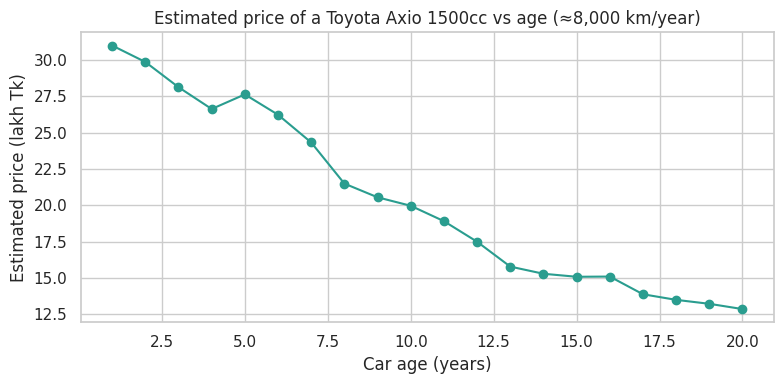

In [31]:
# How does depreciation look for a given car? (price estimate vs. age)
ages = range(1, 21)
est = [predict_price('Toyota', 'Axio', DATA_YEAR - a, 8000 * a, 1500)['estimate'] for a in ages]
plt.figure(figsize=(8, 4))
plt.plot(list(ages), np.array(est)/1e5, marker='o', color='#2a9d8f')
plt.title('Estimated price of a Toyota Axio 1500cc vs age (≈8,000 km/year)')
plt.xlabel('Car age (years)'); plt.ylabel('Estimated price (lakh Tk)')
plt.tight_layout(); plt.show()

## 9. Save the model

In [32]:
import os
artifact = {
    'model': best_model, 'features': FEATURES, 'fuels': FUELS, 'fuel_cols': FUEL_COLS,
    'data_year': DATA_YEAR, 'ratio_lo': RATIO_LO, 'ratio_hi': RATIO_HI, 'metrics': comparison.loc['Random Forest (tuned)'].to_dict(),
}
os.makedirs(SAVE_DIR, exist_ok=True)
path = os.path.join(SAVE_DIR, 'car_price_rf_model.joblib')
joblib.dump(artifact, path, compress=3)
print('Saved to', path)

# To reload later:
# artifact = joblib.load(path); model = artifact['model']

Saved to /content/drive/MyDrive/car_price_rf_model.joblib
